In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, roc_auc_score)

# Load Dataset

In [2]:
df=pd.read_csv("creditcard.csv")
print('Shape:', df.shape)
df.head()

Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [4]:
# Cek missing value dan jumlah duplikat
print('Jumlah missing value:', df.isnull().sum().sum())
print('Jumlah baris duplikat:', df.duplicated().sum())

Jumlah missing value: 0


Jumlah baris duplikat: 1081


# Preprocessing

Distribusi label Class:
Class
0    284315
1       492

Persentase fraud: 0.173% dari seluruh data


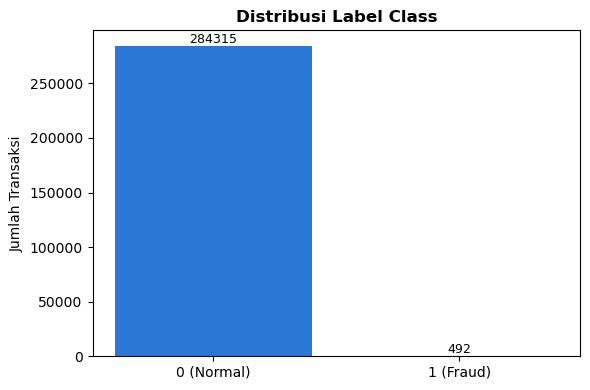

In [5]:
#distribusi kelas pada atribut Class
class_counts = df['Class'].value_counts().sort_index()
print('Distribusi label Class:')
print(class_counts.to_string())
print(f'\nPersentase fraud: {class_counts.loc[1] / len(df) * 100:.3f}% dari seluruh data')

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['0 (Normal)', '1 (Fraud)'], class_counts.values, color=['#2a78d6', '#e8743b'])
ax.set_ylabel('Jumlah Transaksi')
ax.set_title('Distribusi Label Class', fontsize=12, fontweight='bold')
for i, v in enumerate(class_counts.values):
    ax.text(i, v + 5, str(v), ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

In [6]:
# Bagi dataset menjadi data latih dan data uji dengan perbandingan 80:20 (gunakan stratify=y).
# Pisahkan fitur (X) dan target (y)
X = df.drop(columns='Class')
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Proporsi kelas 1 -> train: %.5f, test: %.5f' % (y_train.mean(), y_test.mean()))

Train: (227845, 30) | Test: (56962, 30)
Proporsi kelas 1 -> train: 0.00173, test: 0.00172


In [7]:
# Terapkan metode oversampling (seperti SMOTE) atau undersampling untuk menangani class imbalance. Resampling hanya dilakukan pada data latih, data uji tetap menggunakan distribusi asli.
# Undersampling pada data latih: jumlah kelas 0 disamakan dengan kelas 1 (data uji tidak diubah)
from sklearn.utils import resample

train_df = pd.concat([X_train, y_train], axis=1)
fraud = train_df[train_df['Class'] == 1]
normal = train_df[train_df['Class'] == 0]
normal_sampled = resample(normal, replace=False, n_samples=len(fraud), random_state=42)
train_resampled = pd.concat([fraud, normal_sampled]).sample(frac=1, random_state=42)

X_train_res = train_resampled.drop(columns='Class')
y_train_res = train_resampled['Class']
print('Distribusi kelas setelah resampling:')
print(y_train_res.value_counts().sort_index().to_string())
print('Ukuran data latih baru:', X_train_res.shape, '| Data uji:', X_test.shape)

Distribusi kelas setelah resampling:
Class
0    394
1    394
Ukuran data latih baru: (788, 30) | Data uji: (56962, 30)


In [8]:
# Oversampling dengan SMOTE pada data latih: kelas 1 ditambah data sintetis sampai sama dengan kelas 0 (data uji tidak diubah)
from imblearn.over_sampling import SMOTE

X_train_sm, y_train_sm = SMOTE(random_state=42).fit_resample(X_train, y_train)
print('Distribusi kelas setelah SMOTE:')
print(y_train_sm.value_counts().sort_index().to_string())
print('Ukuran data latih baru:', X_train_sm.shape, '| Data uji:', X_test.shape)

Distribusi kelas setelah SMOTE:
Class
0    227451
1    227451
Ukuran data latih baru: (454902, 30) | Data uji: (56962, 30)


# Modeling


In [9]:
#Menggunakan gradient boosting (XGBoost)
from xgboost import XGBClassifier

param_grid = {'n_estimators': [100, 200], 'learning_rate': [0.05, 0.1], 'max_depth': [3, 5]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_gb = GridSearchCV(XGBClassifier(random_state=42), param_grid, scoring='f1', cv=cv, n_jobs=-1)
grid_gb.fit(X_train_res, y_train_res)
gb = grid_gb.best_estimator_
print('Parameter terbaik:', grid_gb.best_params_)
print('Skor cross validation: %.3f' % grid_gb.best_score_)

# Evaluasi pada data uji (distribusi asli)
pred_gb = gb.predict(X_test)
print('Accuracy: %.3f, Precision: %.3f, Recall: %.3f, F1: %.3f' % (
    accuracy_score(y_test, pred_gb), precision_score(y_test, pred_gb),
    recall_score(y_test, pred_gb), f1_score(y_test, pred_gb)))

Parameter terbaik: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 200}
Skor cross validation: 0.950
Accuracy: 0.955, Precision: 0.034, Recall: 0.918, F1: 0.066


In [10]:
#Bandingkan model tanpa dan dengan penanganan class imbalance.
# Model tanpa penanganan imbalance (data latih asli), parameter sama dengan model terbaik
gb_tanpa = XGBClassifier(random_state=42, **grid_gb.best_params_)
gb_tanpa.fit(X_train, y_train)
pred_tanpa = gb_tanpa.predict(X_test)

# Model dengan oversampling SMOTE, parameter sama dengan model terbaik
gb_smote = XGBClassifier(random_state=42, **grid_gb.best_params_)
gb_smote.fit(X_train_sm, y_train_sm)
pred_smote = gb_smote.predict(X_test)

# Tabel perbandingan metrik pada data uji (distribusi asli)
hasil = {'Tanpa Resampling': (gb_tanpa, pred_tanpa),
         'Dengan Undersampling': (gb, pred_gb),
         'Dengan SMOTE': (gb_smote, pred_smote)}
perbandingan = pd.DataFrame({
    nama: {'Accuracy': accuracy_score(y_test, pred),
           'Precision': precision_score(y_test, pred),
           'Recall': recall_score(y_test, pred),
           'F1': f1_score(y_test, pred),
           'ROC AUC': roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])}
    for nama, (model, pred) in hasil.items()
}).T.round(3)
display(perbandingan)

,Accuracy,Precision,Recall,F1,ROC AUC
Tanpa Resampling,1.000,0.929,0.806,0.863,0.976
Dengan Undersampling,0.955,0.034,0.918,0.066,0.975
Dengan SMOTE,0.997,0.381,0.898,0.535,0.978


Tanpa Resampling
              precision    recall  f1-score   support

           0      1.000     1.000     1.000     56864
           1      0.929     0.806     0.863        98

    accuracy                          1.000     56962
   macro avg      0.965     0.903     0.932     56962
weighted avg      1.000     1.000     1.000     56962

Dengan Undersampling
              precision    recall  f1-score   support

           0      1.000     0.955     0.977     56864
           1      0.034     0.918     0.066        98

    accuracy                          0.955     56962
   macro avg      0.517     0.937     0.522     56962
weighted avg      0.998     0.955     0.976     56962

Dengan SMOTE
              precision    recall  f1-score   support

           0      1.000     0.997     0.999     56864
           1      0.381     0.898     0.535        98

    accuracy                          0.997     56962
   macro avg      0.690     0.948     0.767     56962
weighted avg      0.999

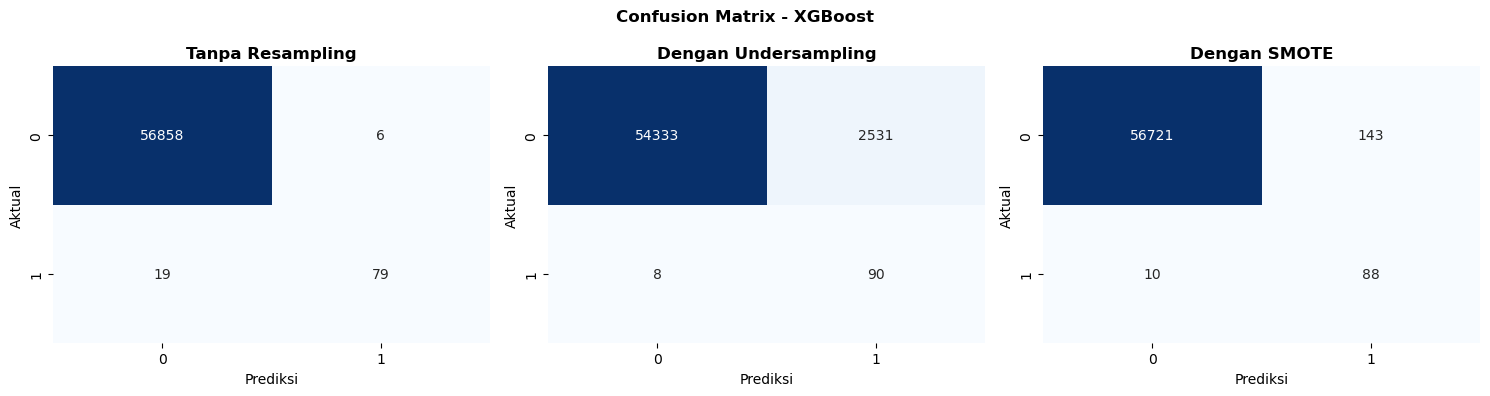

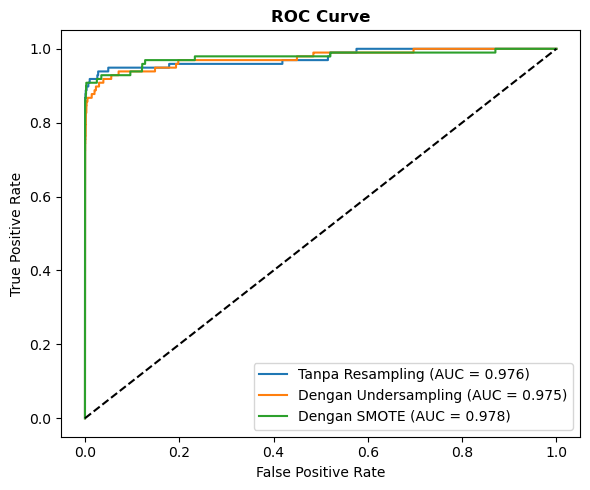

In [11]:
#precision, recall, F1-score, dan AUC-ROC untuk menilai performa model pada kelas minoritas (fraud).
# Classification report ketiga model pada data uji
for nama, (model, pred) in hasil.items():
    print(nama)
    print(classification_report(y_test, pred, digits=3))

# Confusion matrix ketiga model pada data uji
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nama, (model, pred)) in zip(axes, hasil.items()):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(nama, fontweight='bold')
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Aktual')
fig.suptitle('Confusion Matrix - XGBoost', fontweight='bold')
plt.tight_layout()
plt.show()

# Kurva ROC ketiga model pada data uji
plt.figure(figsize=(6, 5))
for nama, (model, pred) in hasil.items():
    proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label='%s (AUC = %.3f)' % (nama, roc_auc_score(y_test, proba)))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

Mengapa accuracy saja tidak cukup untuk dataset ini?
Dataset ini sangat tidak seimbang. Transaksi fraud hanya sekitar 0.17% dari seluruh data, sehingga model yang selalu menebak "normal" sudah mendapat accuracy sekitar 99.8%, padahal tidak mendeteksi satu pun fraud. Karena itu accuracy menutupi kegagalan model pada kelas minoritas (fraud), yang justru menjadi fokus tugas ini.

Untuk itu kita melihat metrik berikut:
- **Precision:** dari transaksi yang diprediksi fraud, berapa yang benar-benar fraud. Precision rendah berarti banyak transaksi normal yang terblokir secara keliru.
- **Recall:** dari seluruh fraud yang ada, berapa yang berhasil terdeteksi. Recall rendah berarti fraud lolos begitu saja, dan ini kesalahan yang paling berbahaya.
- **F1-score:** harmonic mean dari precision dan recall, $F1 = \frac{2 \cdot P \cdot R}{P + R}$, dipakai untuk memilih model terbaik.
- **AUC-ROC:** kemampuan model memisahkan kelas fraud dan normal di berbagai nilai threshold, tanpa bergantung pada satu threshold tertentu.